# Sentiment Analysis on Product Reviews: BERT vs LSTM
Unit 3 – Neural Networks & Deep Learning (Case Study)

### Cell 1 – Install libraries

In [9]:
!pip install -q transformers datasets accelerate

### Cell 2 – Download dataset and preprocessing

In [10]:
import pandas as pd
from datasets import load_dataset

data = load_dataset("SetFit/amazon_reviews_multi_en", split="train")
df = data.to_pandas()[["text", "label"]].drop_duplicates(subset="text")

df["label"] = df["label"].map({0: 0, 1: 0, 2: 1, 3: 2, 4: 2})
class_names = ["Negative", "Neutral", "Positive"]

df = df.groupby("label").sample(n=500, random_state=42).reset_index(drop=True)
df["sentiment"] = df["label"].map(dict(enumerate(class_names)))

print(df["sentiment"].value_counts())
df.sample(5, random_state=1)

sentiment
Negative    500
Neutral     500
Positive    500
Name: count, dtype: int64


,text,label,sentiment
91,my grandson has not even gotten to sleep in th...,0,Negative
75,I don't think our house has particularly high ...,0,Negative
1264,Feels a bit thin and light but does the job!,2,Positive
330,Soooooo tiny you can't tell what is. Save your...,0,Negative
1349,I bought this as a gift and he loves it.,2,Positive


### Cell 3 – Split dataset

In [11]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=42)

print("Train:", len(train_df), "Validation:", len(val_df), "Test:", len(test_df))

Train: 1050 Validation: 225 Test: 225


### Cell 4 – LSTM model using PyTorch

In [12]:
import re
import torch
import torch.nn as nn
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, accuracy_score, f1_score

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Vocabulary is built from training data only (no leakage)
words = Counter(w for t in train_df["text"] for w in re.findall(r"[a-z']+", t.lower()))
vocab = {w: i + 2 for i, (w, _) in enumerate(words.most_common(5000))}  # 0 = padding, 1 = unknown

def encode(text, max_len=100):
    ids = [vocab.get(w, 1) for w in re.findall(r"[a-z']+", text.lower())][:max_len]
    return [0] * (max_len - len(ids)) + ids

def make_loader(d, shuffle):
    x = torch.tensor([encode(t) for t in d["text"]])
    y = torch.tensor(d["label"].values)
    return DataLoader(TensorDataset(x, y), batch_size=32, shuffle=shuffle)

train_loader = make_loader(train_df, True)
val_loader = make_loader(val_df, False)
test_loader = make_loader(test_df, False)

class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Embedding(len(vocab) + 2, 100, padding_idx=0)
        self.lstm = nn.LSTM(100, 128, batch_first=True)
        self.fc = nn.Linear(128, 3)

    def forward(self, x):
        _, (h, _) = self.lstm(self.embed(x))
        return self.fc(h[-1])

def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in loader:
            preds += model(x.to(device)).argmax(dim=1).cpu().tolist()
    return preds

lstm = LSTMModel().to(device)
optimizer = torch.optim.Adam(lstm.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()
best_acc = 0

for epoch in range(15):
    lstm.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(lstm(x), y)
        loss.backward()
        optimizer.step()
    val_acc = accuracy_score(val_df["label"], predict(lstm, val_loader))
    print(f"Epoch {epoch + 1}: loss = {loss.item():.3f}, val accuracy = {val_acc:.3f}")
    if val_acc > best_acc:
        best_acc = val_acc
        best_weights = {k: v.clone() for k, v in lstm.state_dict().items()}

lstm.load_state_dict(best_weights)
lstm_preds = predict(lstm, test_loader)

print(classification_report(test_df["label"], lstm_preds, target_names=class_names))
lstm_acc = accuracy_score(test_df["label"], lstm_preds)
lstm_f1 = f1_score(test_df["label"], lstm_preds, average="weighted")

Epoch 1: loss = 1.097, val accuracy = 0.369
Epoch 2: loss = 1.017, val accuracy = 0.400
Epoch 3: loss = 0.912, val accuracy = 0.444
Epoch 4: loss = 0.804, val accuracy = 0.453
Epoch 5: loss = 0.628, val accuracy = 0.462
Epoch 6: loss = 0.353, val accuracy = 0.444
Epoch 7: loss = 0.265, val accuracy = 0.453
Epoch 8: loss = 0.107, val accuracy = 0.436
Epoch 9: loss = 0.042, val accuracy = 0.458
Epoch 10: loss = 0.033, val accuracy = 0.498
Epoch 11: loss = 0.022, val accuracy = 0.458
Epoch 12: loss = 0.011, val accuracy = 0.467
Epoch 13: loss = 0.013, val accuracy = 0.462
Epoch 14: loss = 0.005, val accuracy = 0.484
Epoch 15: loss = 0.004, val accuracy = 0.476
              precision    recall  f1-score   support

    Negative       0.45      0.31      0.37        75
     Neutral       0.42      0.36      0.39        75
    Positive       0.47      0.69      0.56        75

    accuracy                           0.45       225
   macro avg       0.45      0.45      0.44       225
weighted

### Cell 5 – Load and tokenize BERT

In [13]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=128)

def prepare(d):
    return Dataset.from_pandas(d[["text", "label"]], preserve_index=False).map(tokenize, batched=True)

train_ds = prepare(train_df)
val_ds = prepare(val_df)
test_ds = prepare(test_df)

Map:   0%|          | 0/1050 [00:00<?, ? examples/s]

Map:   0%|          | 0/225 [00:00<?, ? examples/s]

Map:   0%|          | 0/225 [00:00<?, ? examples/s]

### Cell 6 – Fine-tune BERT

In [6]:
model = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=3)

args = TrainingArguments(
    output_dir="bert_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=42,
)

def compute_metrics(p):
    return {"accuracy": accuracy_score(p.label_ids, p.predictions.argmax(axis=1))}

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.868636,0.657778
2,No log,0.789304,0.631111
3,No log,0.748276,0.684444


TrainOutput(global_step=198, training_loss=0.8241277367177636, metrics={'train_runtime': 24.1025, 'train_samples_per_second': 130.692, 'train_steps_per_second': 8.215, 'total_flos': 207201816460800.0, 'train_loss': 0.8241277367177636, 'epoch': 3.0})

### Cell 7 – Test BERT

In [7]:
bert_preds = trainer.predict(test_ds).predictions.argmax(axis=1)

print(classification_report(test_df["label"], bert_preds, target_names=class_names))
bert_acc = accuracy_score(test_df["label"], bert_preds)
bert_f1 = f1_score(test_df["label"], bert_preds, average="weighted")

              precision    recall  f1-score   support

    Negative       0.70      0.75      0.72        75
     Neutral       0.59      0.48      0.53        75
    Positive       0.75      0.84      0.79        75

    accuracy                           0.69       225
   macro avg       0.68      0.69      0.68       225
weighted avg       0.68      0.69      0.68       225



### Cell 8 – Compare both models

Model  Accuracy  Weighted F1 Score
 LSTM    0.4533             0.4386
 BERT    0.6889             0.6815


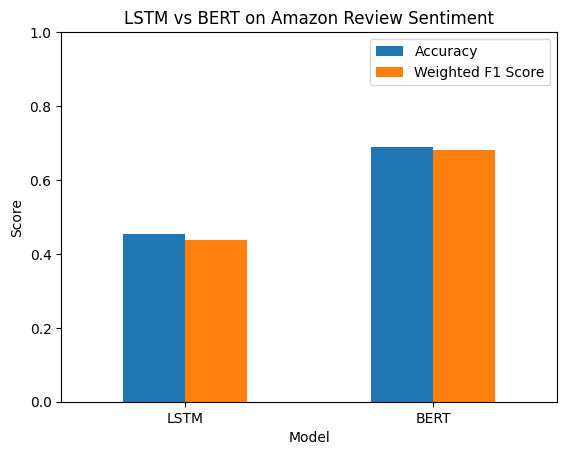

In [8]:
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": ["LSTM", "BERT"],
    "Accuracy": [lstm_acc, bert_acc],
    "Weighted F1 Score": [lstm_f1, bert_f1],
})
print(results.round(4).to_string(index=False))

results.plot(x="Model", kind="bar", rot=0, ylim=(0, 1))
plt.title("LSTM vs BERT on Amazon Review Sentiment")
plt.ylabel("Score")
plt.show()